# COD-SSI — performance analysis

This notebook regenerates the experimental figures of Section 5 of the paper from the raw benchmark data in `../performancesData/`.
It loads the COD-SSI measurements (`COD-ssi.json`) and the classical hash-based selective-disclosure baseline (`hash-SD.json`), reshapes them into tidy `pandas` data frames, and renders one figure per analysis level (per-claim, VC, VP, `D_VP`, and OPRF), saving each as a PDF under `imgs/`.

> **Note.** The released `COD-ssi.json` is a 100-run subset of the full 1000-run campaign, so regenerated figures are statistically faithful but might differ slightly from the published ones.

In [1]:
import json
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
import pandas as pd
import os

# Figures are written to analysis/imgs/
os.makedirs("imgs", exist_ok=True)

### Benchmark data layout

Each entry in the JSON datasets corresponds to one experimental configuration (a credential with `claimsInVC` claims) and stores the raw measurements collected across all runs.
Two families of arrays are recorded.

**Per-run arrays** (one value per run, length `#runs`):

- `VCcreationTime` — total time to create a Verifiable Credential.
- `VCsize` — size of the VC.
- `VCmetadataSize` — size of the VC credential data `D_VC`.
- `VCverificationTime` — total time to verify the VC.
- `VPcreationTime` — total time to create a Verifiable Presentation (includes claim encryption).
- `VPsize` — size of the VP.
- `VPmetadataSize` — size of the encrypted presentation data `D_VP`.
- `VPverificationTime` — total time to verify the VP.
- `SDrequestTime` — total time to compute the oblivious disclosure request (Verifier).
- `SDrequestSize` — size of the disclosure request.
- `SDresponseTime` — total time to compute the oblivious disclosure response (Holder).
- `SDresponseSize` — size of the disclosure response.
- `SDdecryptionTime` — total time to decrypt the disclosed claims (Verifier).
- `SDverificationTime` — total time to re-verify the claim commitments (Verifier).

**Per-claim arrays** (one value per claim per run, length `#runs × #claims`):

- `VCcreationClaimHashingTime` — time to hash a single claim (Issuer).
- `VPcreationClaimEncryptionTime` — time to encrypt a single claim (Holder).
- `SDrequestTimeClaim` — time to compute the request for a single claim (Verifier).
- `SDresponseTimeClaim` — time to compute the response for a single claim (Holder).
- `SDdecryptionClaimTime` — time to decrypt a single claim (Verifier).
- `SDverificationClaimTime` — time to re-verify a single claim commitment (Verifier).

The `hash-SD.json` reference dataset records only the per-run arrays.

In [2]:
# Measurement keys, split by granularity:
#   run-based   -> one value per run
#   claim-based -> one value per claim per run
run_based_keys = [
    "VCcreationTime",
    "VCsize",
    "VCmetadataSize",
    "VCverificationTime",
    "VPcreationTime",
    "VPsize",
    "VPmetadataSize",
    "VPverificationTime",
    "SDrequestTime",
    "SDrequestSize",
    "SDresponseTime",
    "SDresponseSize",
    "SDdecryptionTime",
    "SDverificationTime",
]

claim_based_keys = [
    "VCcreationClaimHashingTime",
    "VPcreationClaimEncryptionTime",
    "SDrequestTimeClaim",
    "SDresponseTimeClaim",
    "SDdecryptionClaimTime",
    "SDverificationClaimTime",
]

# Apply a shared, log-scaled time (left) and size (right) axis to a dual-axis plot.
def setTicks(ax1, ax2):
    
    ax1.set_ylabel("Time")
    ax1.set_yscale('log')
    ax1.set_ylim([.8, 20000])
    ax1.set_yticks([10**i for i in range(5)])
    ax1.set_yticklabels(["1 ms", "10 ms", "100 ms", "1 s", "10 s"])

    
    ax2.set_ylabel("Size")
    ax2.set_yscale('log')
    ax2.set_ylim([100, 5000000])
    ax2.set_yticks([10**i for i in range(2, 7)])
    ax2.set_yticklabels(["100 B", "1 kB", "10 kB", "100 kB", "1 MB"])

## Extract the benchmark data on a DataFrame

`build_dataframes` flattens the nested JSON into two tidy frames: `df_runs` (one row per run) and `df_claims` (one row per claim per run).

In [3]:
def build_dataframes(path):
    """Flatten the nested benchmark JSON into two tidy data frames.

    Returns (data, df_runs, df_claims): df_runs has one row per run, df_claims
    one row per claim per run.
    """
    with open(path, "r") as f:
        data = json.load(f)

    global run_based_keys, claim_based_keys

    df_runs_list = []
    df_claims_list = []

    for exp in data:
        claims = exp["claimsInVC"]
        n_runs = len(exp["VCcreationTime"])  # assume consistent lengths
        n_claim_vals = len(exp["VPcreationClaimEncryptionTime"])
        assert n_claim_vals == n_runs * claims

        # build run-based rows
        for i in range(n_runs):
            row = {"claimsInVC": claims}
            for key in run_based_keys:
                if key in exp:
                    row[key] = exp[key][i]

            # Sum the per-claim encryption/decryption costs over this run, to
            # isolate the D_VP overhead that COD-SSI adds.
            start = i * claims
            end = (i + 1) * claims
            enc_sum = sum(exp["VPcreationClaimEncryptionTime"][start:end])
            dec_sum = sum(exp["SDdecryptionClaimTime"][start:end])
            row["VPencryptionTime"] = enc_sum
            row["VPdecryptionTime"] = dec_sum
            # Keep the raw VP creation time as *_SD, then strip the encryption
            # cost so VPcreationTime measures the plain hash-based SD VP alone.
            row["VPcreationTime_SD"] = row["VPcreationTime"]
            row["VPcreationTime"] = row["VPcreationTime"] - enc_sum

            df_runs_list.append(row)

        # build claim-based rows
        for i in range(n_claim_vals):
            row = {"claimsInVC": claims}
            for key in claim_based_keys:
                if key in exp:
                    row[key] = exp[key][i]
            df_claims_list.append(row)

    df_runs = pd.DataFrame(df_runs_list)
    df_claims = pd.DataFrame(df_claims_list)
    return data, df_runs, df_claims



data, df_runs, df_claims = build_dataframes("../performancesData/COD-ssi.json")

## Plot per-claim statistics

Per-claim costs are independent of the credential size, so all claims are pooled into a single broken-axis boxplot (paper Figure “per-claim statistics”), annotated with the average, maximum, and outlier fraction of each operation.

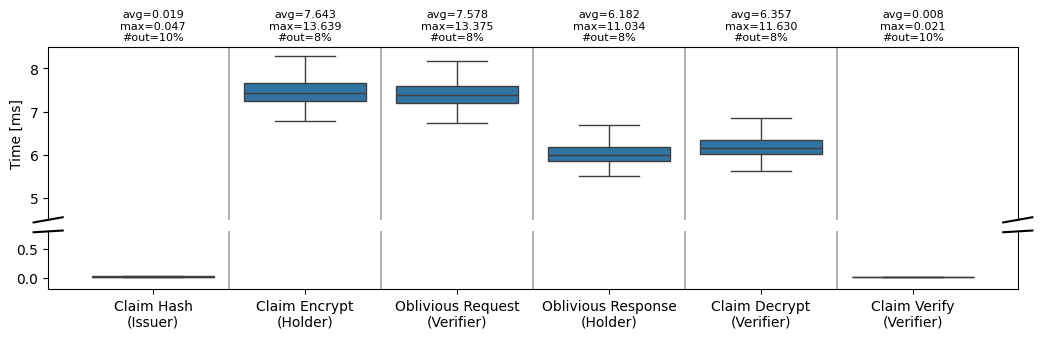

In [4]:
scale=.5

xtick_labels = {
    "VCcreationClaimHashingTime": "Claim Hash\n(Issuer)",
    "VPcreationClaimEncryptionTime": "Claim Encrypt\n(Holder)",
    "SDrequestTimeClaim": "Oblivious Request\n(Verifier)",
    "SDresponseTimeClaim": "Oblivious Response\n(Holder)",
    "SDdecryptionClaimTime": "Claim Decrypt\n(Verifier)",
    "SDverificationClaimTime": "Claim Verify\n(Verifier)"
}

alpha=0.6,
trim_pct=0.01  # fraction to trim from top and bottom per metric (e.g., 0.01 for 1%)

# Optionally trim top/bottom k% per metric
df_trimmed = df_claims.copy()
if trim_pct > 0:
    for key in claim_based_keys:
        lower = df_trimmed[key].quantile(trim_pct)
        upper = df_trimmed[key].quantile(1 - trim_pct)
        df_trimmed[key] = df_trimmed[key].clip(lower=lower, upper=upper)

df_long = df_trimmed.melt(
    value_vars=claim_based_keys,
    var_name="metric",
    value_name="value"
)

# Tukey 1.5*IQR rule, used only to *count* outliers for the annotation
# (the boxes themselves are drawn with showfliers=False).
def compute_outlier_mask(g):
    q1 = g.quantile(0.25)
    q3 = g.quantile(0.75)
    iqr = q3 - q1
    lower = q1 - 1.5 * iqr
    upper = q3 + 1.5 * iqr
    return (g < lower) | (g > upper)

metric_stats = {}
outlier_rows = []
for key in claim_based_keys:
    vals = df_trimmed[key].dropna()
    mask = compute_outlier_mask(vals)
    out_vals = vals[mask]
    metric_stats[key] = {
        "max": vals.max() if len(vals) else np.nan,
        "avg": vals.mean() if len(vals) else np.nan,
        "n_outliers": int(mask.sum()) / len(vals) if len(vals) else 0,
    }

df_outliers = pd.concat(outlier_rows, ignore_index=True) if outlier_rows else pd.DataFrame(columns=["metric","value"])

fig, (axt, axb) = plt.subplots(
    2, 1, sharex=True, figsize=(21*scale, 7*scale),
    gridspec_kw={'height_ratios':[3, 1]}  # adjust proportions
)

# Two stacked axes form a broken y-axis: the bottom shows the sub-millisecond
# operations (hash, verify), the top the ~6-8 ms elliptic-curve ones.
for ax, ylim in [(axb, [-.2, .8]), (axt, [4.5, 8.5])]:
    sns.boxplot(
        ax=ax,
        data=df_long,
        x="metric",
        y="value",
        order=claim_based_keys,
        showfliers=False
    )        

    # Annotate data above the boxplots
    if ax == axt:
        for i, key in enumerate(claim_based_keys):
            m = metric_stats[key]["max"]
            avg = metric_stats[key]["avg"]
            n_out = metric_stats[key]["n_outliers"]
            if np.isfinite(m):
                y_text = 8.6
                ax.text(
                    i,
                    y_text,
                    f"avg={avg:4.3f}\nmax={m:4.3f}\n#out={n_out:.0%}",
                    ha="center",
                    va="bottom",
                    fontsize=8,
                    rotation=0
                )
    ax.set_xlabel("")
    ax.set_ylim(ylim)

axb.set_yticks([0, 0.5])

axt.set_xticks([])
axt.tick_params(axis="x", which="both", bottom=False, top=False)
axb.set_xticks(range(len(claim_based_keys)))
if xtick_labels:
    axb.set_xticklabels([xtick_labels[k] for k in claim_based_keys])

axt.spines["bottom"].set_visible(False)
axb.spines["top"].set_visible(False)

# compute ratio of axis height to width in display coordinates
inv = axt.transAxes.inverted()
x0, y0 = axt.transAxes.transform((0,0))
x1, y1 = axt.transAxes.transform((1,1))
aspect = (y1-y0) / (x1-x0)  # height/width

# Diagonal lines to indicate broken axis
d = .015  # size of diagonal lines
kwargs = dict(transform=axt.transAxes, color="k", clip_on=False)
axt.plot((-d, +d), (-d, +d), **kwargs)        # top-left diagonal
axt.plot((1 - d, 1 + d), (-d, +d), **kwargs)  # top-right diagonal

kwargs.update(transform=axb.transAxes)  # switch to bottom axes
axb.plot((-d, +d), (1 - d, 1 + d), **kwargs)  # bottom-left diagonal
axb.plot((1 - d, 1 + d), (1 - d, 1 + d), **kwargs)  # bottom-right diagonal

axt.set_ylabel(f"Time [ms]")
axb.set_ylabel("")

for i in range(1,len(claim_based_keys)):
    axb.axvline(i-.5, color='k', alpha=.3)
    axt.axvline(i-.5, color='k', alpha=.3)


fig.tight_layout()
fig.subplots_adjust(hspace=0.1)

fig.savefig("imgs/perclaim_stats_cut.pdf")

## Plot VC-related statistics

Verifiable Credential creation and verification times (left axis, boxplots) against the VC and `D_VC` sizes (right axis, bars), as a function of the claim count.

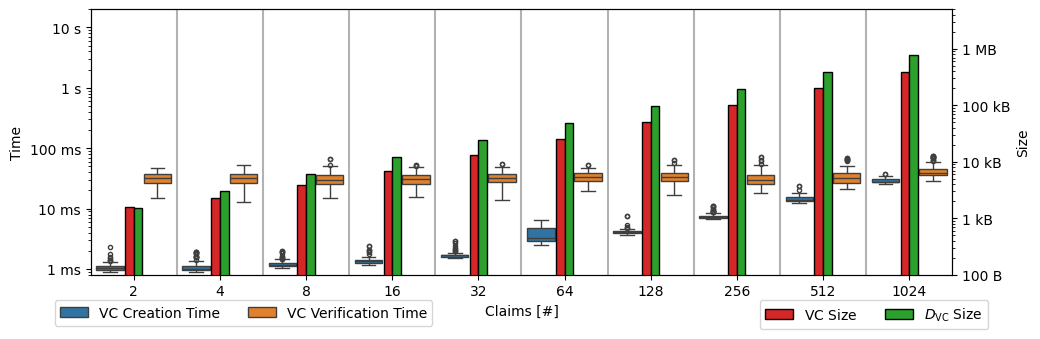

In [5]:
# Dual-axis figure (the same idiom is reused by the VP, D_VP and OPRF cells):
#   left  axis -> timings as boxplots (trimmed at 1% per metric, per claim count)
#   right axis -> mean object sizes as bars
# Prepare boxplot data
df_long = pd.melt(
    df_runs,
    id_vars=["claimsInVC"],
    value_vars=["VCcreationTime", "VCverificationTime"],
    var_name="metric",
    value_name="value"
)

# --- Trim top and bottom 1% per metric ---
trim_pct = 0.01
df_trimmed = df_long.copy()

for metric in df_long["metric"].unique():
    for claim_count in df_long["claimsInVC"].unique():
        mask = (df_long["metric"] == metric) & (df_long["claimsInVC"] == claim_count)
        vals = df_long.loc[mask, "value"]
        if len(vals) == 0:
            continue
        lower = vals.quantile(trim_pct)
        upper = vals.quantile(1 - trim_pct)
        df_trimmed.loc[mask, "value"] = vals.clip(lower=lower, upper=upper)

fig, ax = plt.subplots(figsize=(21*scale, 7*scale))

sns.boxplot(
    ax=ax, data=df_trimmed,
    x="claimsInVC", y="value", hue="metric",
    flierprops={"marker": "."},
    gap=0.42,
    width=1.1
)
ax.set_xlabel("Claims [#]")

ax2 = ax.twinx()

df_size = df_runs.groupby("claimsInVC")[["VCmetadataSize", "VCsize"]].mean().reset_index()

bar_width = 0.1
x = np.arange(len(df_size))

ax2.bar(
    x-.05, df_size["VCsize"],
    width=bar_width, facecolor="C3", label="$\\mathsf{VC}$ Size", edgecolor='k'
)
ax2.bar(
    x+.05, df_size["VCmetadataSize"],
    width=bar_width, color="C2", label="$D_\\mathsf{VC}$ Size", edgecolor='k'
)

ax.set_xticks(x)
ax.set_xticklabels(df_size["claimsInVC"])
ax.set_xlim([-.5, 9.5])


metric_labels = {
    "VCcreationTime": "VC Creation Time",
    "VCverificationTime": "VC Verification Time"
}
handles, labels = ax.get_legend_handles_labels()
new_labels = [metric_labels.get(lbl, lbl) for lbl in labels]
ax.legend(handles, new_labels, title="", loc="upper left", bbox_to_anchor=(-.05, -0.07), ncols=2)

ax2.legend(loc="upper right", bbox_to_anchor=(1.05, -0.07), ncols=2)

for xt in range(9):
    ax.axvline( xt+.5, color='k', alpha=.3 )

setTicks(ax, ax2)

fig.tight_layout()
fig.savefig("imgs/VC_stats.pdf")

## Plot VP-related statistics

Verifiable Presentation creation and verification times (left axis) and VP size (right axis); this is the classical hash-based SD presentation that COD-SSI builds upon.

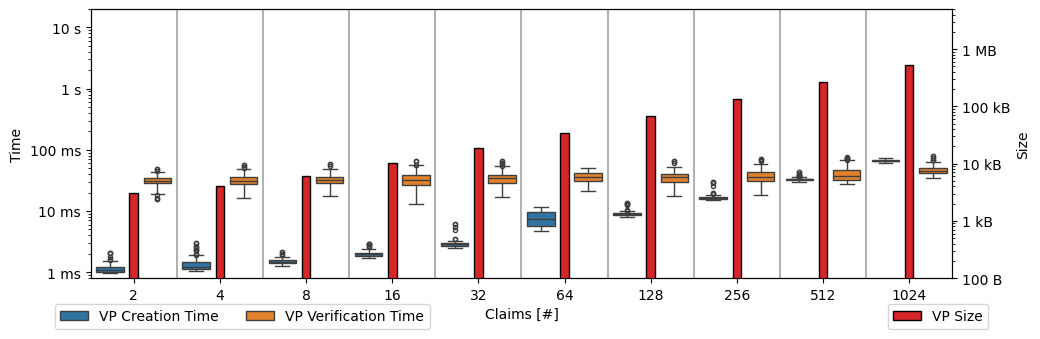

In [6]:
# Prepare boxplot data
df_long = pd.melt(
    df_runs,
    id_vars=["claimsInVC"],
    value_vars=["VPcreationTime", "VPverificationTime"],
    var_name="metric",
    value_name="value"
)

# --- Trim top and bottom 1% per metric ---
trim_pct = 0.01
df_trimmed = df_long.copy()

for metric in df_long["metric"].unique():
    for claim_count in df_long["claimsInVC"].unique():
        mask = (df_long["metric"] == metric) & (df_long["claimsInVC"] == claim_count)
        vals = df_long.loc[mask, "value"]
        if len(vals) == 0:
            continue
        lower = vals.quantile(trim_pct)
        upper = vals.quantile(1 - trim_pct)
        df_trimmed.loc[mask, "value"] = vals.clip(lower=lower, upper=upper)

fig, ax = plt.subplots(figsize=(21*scale, 7*scale))

sns.boxplot(
    ax=ax, data=df_trimmed,
    x="claimsInVC", y="value", hue="metric",
    flierprops={"marker": "."},
    gap=0.42,
    width=1.1
)
ax.legend([],[], frameon=False)
ax.set_xlabel("Claims [#]")

ax2 = ax.twinx()

df_size = df_runs.groupby("claimsInVC")[["VPmetadataSize", "VPsize"]].mean().reset_index()

bar_width = 0.1
x = np.arange(len(df_size))

ax2.bar(
    x, df_size["VPsize"],
    width=bar_width, facecolor="C3", label="VP Size", edgecolor='k'
)

ax.set_xticks(x)
ax.set_xticklabels(df_size["claimsInVC"])
ax.set_xlim([-.5, 9.5])

metric_labels = {
    "VPcreationTime": "VP Creation Time",
    "VPverificationTime": "VP Verification Time"
}
handles, labels = ax.get_legend_handles_labels()
new_labels = [metric_labels.get(lbl, lbl) for lbl in labels]
ax.legend(handles, new_labels, title="", loc="upper left", bbox_to_anchor=(-.05, -0.07), ncols=2)

ax2.legend(loc="upper right", bbox_to_anchor=(1.05, -0.07), ncols=2)

for xt in range(9):
    ax.axvline( xt+.5, color='k', alpha=.3 )

setTicks(ax, ax2)

fig.tight_layout()
fig.savefig("imgs/VP_stats.pdf")

## Plot D_VP-related statistics

Overhead that COD-SSI adds on top of a plain VP: the time to encrypt (Holder) and decrypt (Verifier) the claim payload `D_VP`, against its size.

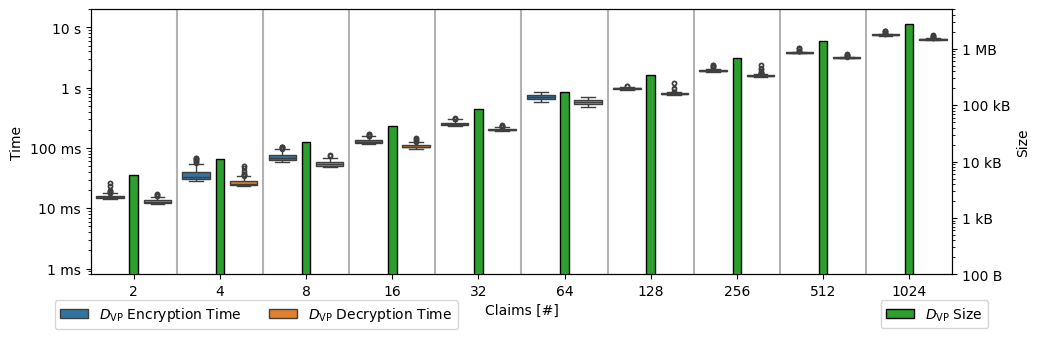

In [7]:
# Prepare boxplot data
df_long = pd.melt(
    df_runs,
    id_vars=["claimsInVC"],
    value_vars=["VPencryptionTime", "VPdecryptionTime"],
    var_name="metric",
    value_name="value"
)

# --- Trim top and bottom 1% per metric ---
trim_pct = 0.01
df_trimmed = df_long.copy()

for metric in df_long["metric"].unique():
    for claim_count in df_long["claimsInVC"].unique():
        mask = (df_long["metric"] == metric) & (df_long["claimsInVC"] == claim_count)
        vals = df_long.loc[mask, "value"]
        if len(vals) == 0:
            continue
        lower = vals.quantile(trim_pct)
        upper = vals.quantile(1 - trim_pct)
        df_trimmed.loc[mask, "value"] = vals.clip(lower=lower, upper=upper)

fig, ax = plt.subplots(figsize=(21*scale, 7*scale))

sns.boxplot(
    ax=ax, data=df_trimmed,
    x="claimsInVC", y="value", hue="metric",
    flierprops={"marker": "."},
    gap=0.42,
    width=1.1
)
ax.legend([],[], frameon=False)
ax.set_xlabel("Claims [#]")


ax2 = ax.twinx()

df_size = df_runs.groupby("claimsInVC")[["VPmetadataSize", "VPsize"]].mean().reset_index()

bar_width = 0.1
x = np.arange(len(df_size))

ax2.bar(
    x, df_size["VPmetadataSize"],
    width=bar_width, color="C2", label="$D_\\mathsf{VP}$ Size", edgecolor='k'
)

ax.set_xticks(x)
ax.set_xticklabels(df_size["claimsInVC"])
ax.set_xlim([-.5, 9.5])

metric_labels = {
    "VPencryptionTime": "$D_\\mathsf{VP}$ Encryption Time",
    "VPdecryptionTime": "$D_\\mathsf{VP}$ Decryption Time"
}
handles, labels = ax.get_legend_handles_labels()
new_labels = [metric_labels.get(lbl, lbl) for lbl in labels]
ax.legend(handles, new_labels, title="", loc="upper left", bbox_to_anchor=(-.05, -0.07), ncols=2)

ax2.legend(loc="upper right", bbox_to_anchor=(1.05, -0.07), ncols=2)

for xt in range(9):
    ax.axvline( xt+.5, color='k', alpha=.3 )

setTicks(ax, ax2)

fig.tight_layout()
fig.savefig("imgs/D_VP_stats.pdf")

## Plot OPRF-related statistics

Cost of the oblivious interaction when all claims are retrieved: request (Verifier) and response (Holder) times and message sizes.

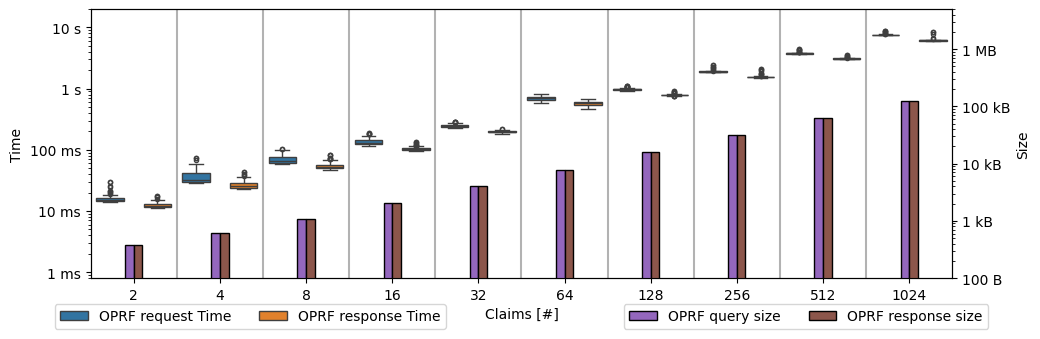

In [8]:
# Prepare boxplot data
df_long = pd.melt(
    df_runs,
    id_vars=["claimsInVC"],
    value_vars=["SDrequestTime", "SDresponseTime"],
    var_name="metric",
    value_name="value"
)

trim_pct = 0.01
df_trimmed = df_long.copy()

for metric in df_long["metric"].unique():
    for claim_count in df_long["claimsInVC"].unique():
        mask = (df_long["metric"] == metric) & (df_long["claimsInVC"] == claim_count)
        vals = df_long.loc[mask, "value"]
        if len(vals) == 0:
            continue
        lower = vals.quantile(trim_pct)
        upper = vals.quantile(1 - trim_pct)
        df_trimmed.loc[mask, "value"] = vals.clip(lower=lower, upper=upper)


fig, ax = plt.subplots(figsize=(21*scale, 7*scale))

sns.boxplot(
    ax=ax, data=df_trimmed,
    x="claimsInVC", y="value", hue="metric",
    flierprops={"marker": "."},
    gap=0.42,
    width=1.1
)
ax.legend([],[], frameon=False)
ax.set_xlabel("Claims [#]")

ax2 = ax.twinx()

df_size = df_runs.groupby("claimsInVC")[["SDrequestSize", "SDresponseSize"]].mean().reset_index()

bar_width = 0.1
x = np.arange(len(df_size))

ax2.bar(
    x-.05, df_size["SDrequestSize"],
    width=bar_width, facecolor="C4", label="OPRF query size", edgecolor='k'
)
ax2.bar(
    x+.05, df_size["SDresponseSize"],
    width=bar_width, color="C5", label="OPRF response size", edgecolor='k'
)

ax.set_xticks(x)
ax.set_xticklabels(df_size["claimsInVC"])
ax.set_xlim([-.5, 9.5])


metric_labels = {
    "SDrequestTime": "OPRF request Time",
    "SDresponseTime": "OPRF response Time"
}
handles, labels = ax.get_legend_handles_labels()
new_labels = [metric_labels.get(lbl, lbl) for lbl in labels]
ax.legend(handles, new_labels, title="", loc="upper left", bbox_to_anchor=(-.05, -0.07), ncols=2)

ax2.legend(loc="upper right", bbox_to_anchor=(1.05, -0.07), ncols=2)

for xt in range(9):
    ax.axvline( xt+.5, color='k', alpha=.3 )


setTicks(ax, ax2)

fig.tight_layout()
fig.savefig("imgs/oprf_stats.pdf")

## Import reference dataset (only per-run statistics)

Load the classical hash-based selective-disclosure baseline (`hash-SD.json`), which records per-run arrays only.

In [9]:
def build_runs_reference(path):
    with open(path, "r") as f:
        data = json.load(f)

    global run_based_keys

    df_runs_list = []
    for exp in data:
        claims = exp["claimsInVC"]
        n_runs = len(exp["VCcreationTime"])
        for i in range(n_runs):
            row = {"claimsInVC": claims}
            for key in run_based_keys:
                if key in exp:
                    row[key] = exp[key][i]
            df_runs_list.append(row)

    df_runs = pd.DataFrame(df_runs_list)
    return data, df_runs

_, df_hash = build_runs_reference("../performancesData/hash-SD.json")

## Plot hash SD-related reference statistics

Baseline request/response times and sizes for non-oblivious hash-based SD, for comparison with the OPRF interaction above (note the finer, microsecond-scale time axis).

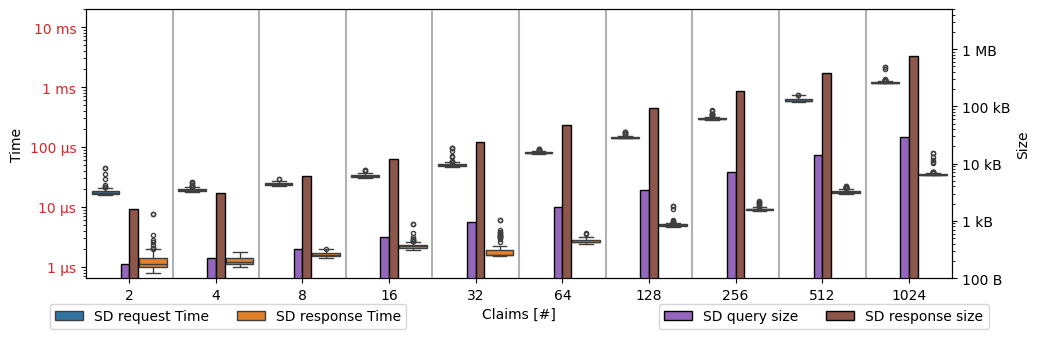

In [10]:
# Prepare boxplot data
df_long = pd.melt(
    df_hash,
    id_vars=["claimsInVC"],
    value_vars=["SDrequestTime", "SDresponseTime"],
    var_name="metric",
    value_name="value"
)

trim_pct = 0.01
df_trimmed = df_long.copy()

for metric in df_long["metric"].unique():
    for claim_count in df_long["claimsInVC"].unique():
        mask = (df_long["metric"] == metric) & (df_long["claimsInVC"] == claim_count)
        vals = df_long.loc[mask, "value"]
        if len(vals) == 0:
            continue
        lower = vals.quantile(trim_pct)
        upper = vals.quantile(1 - trim_pct)
        df_trimmed.loc[mask, "value"] = vals.clip(lower=lower, upper=upper)


fig, ax = plt.subplots(figsize=(21*scale, 7*scale))

sns.boxplot(
    ax=ax, data=df_trimmed,
    x="claimsInVC", y="value", hue="metric",
    flierprops={"marker": "."},
    gap=0.42,
    width=1.1
)
ax.legend([],[], frameon=False)
ax.set_xlabel("Claims [#]")

ax2 = ax.twinx()

df_size = df_hash.groupby("claimsInVC")[["SDrequestSize", "SDresponseSize"]].mean().reset_index()

bar_width = 0.1
x = np.arange(len(df_size))

ax2.bar(
    x-.05, df_size["SDrequestSize"],
    width=bar_width, facecolor="C4", label="SD query size", edgecolor='k'
)
ax2.bar(
    x+.05, df_size["SDresponseSize"],
    width=bar_width, color="C5", label="SD response size", edgecolor='k'
)

ax.set_xticks(x)
ax.set_xticklabels(df_size["claimsInVC"])
ax.set_xlim([-.5, 9.5])

metric_labels = {
    "SDrequestTime": "SD request Time",
    "SDresponseTime": "SD response Time"
}
handles, labels = ax.get_legend_handles_labels()
new_labels = [metric_labels.get(lbl, lbl) for lbl in labels]
ax.legend(handles, new_labels, title="", loc="upper left", bbox_to_anchor=(-.05, -0.07), ncols=2)

ax2.legend(loc="upper right", bbox_to_anchor=(1.05, -0.07), ncols=2)

for xt in range(9):
    ax.axvline( xt+.5, color='k', alpha=.3 )

setTicks(ax, ax2)
ax.set_yscale('log')
ax.set_ylim([0.00065, 20])
ax.set_yticks([10**i for i in range(-3, 2)])
ax.set_yticklabels(["1 μs", "10 μs", "100 μs", "1 ms", '10 ms'], color='C3')

fig.tight_layout()
fig.savefig("imgs/hash_stats.pdf")